# Chapter 6 Case Study: Training a Reasoning Model with RLVR (GRPO) on GSM8K

**Goal:** demonstrate **GRPO > SFT > baseline** on verifiable math reasoning, using a *binary* reward from an automatic verifier.

This notebook mirrors the Chapter 6 Case Study framing and outputs:
- **Figure 1:** Learning curves (Pass@1/4/8 vs GRPO steps)
- **Figure 2:** Test-time compute scaling (best-of-\(N\))
- **Figure 3:** Example trajectories (early vs late policy)
- **Extra Diagnostic Figure 4:** Reasoning quality evolution (length / steps / math markers)

Design constraints:
- **Package-based** (core logic imported from `rlbook`)
- **Simple** (no LoRA, no quantization)
- **Faithful** GRPO/RLVR (group sampling, verifier reward, clipped objective, no critic)

## Case Study framing (matches Chapter 6)

### Problem and Objective
We want to show that **reinforcement learning with verifiable rewards (RLVR)** can improve a model’s mathematical reasoning without requiring human preference labels.

Concretely, we test three claims:
1. **Accuracy:** GRPO improves **Pass@k** beyond a base model and beyond a CoT SFT baseline.
2. **Test-time compute scaling:** best-of-\(N\) sampling improves success, and GRPO can increase the slope of this scaling.
3. **Reasoning behavior:** as a side effect (not a training target), reasoning becomes more structured (length/steps/math usage).

### Methodology (high level)
We compare three policies on GSM8K:
- **Base**: an instruction-tuned model prompted with a strict `FINAL:` contract.
- **SFT (CoT)**: supervised fine-tuning on GSM8K worked solutions (teacher forcing).
- **GRPO (RLVR)**: starting from SFT, we optimize **binary verifier rewards** using GRPO (critic-free PPO-style updates).

Metrics:
- **Pass@k** for \(k \in \{1,4,8\}\) (learning curves) and \(k \in \{1,2,4,8,16\}\) (compute scaling).
- Diagnostics (analysis-only): **token length**, **step count heuristic**, **math marker count**, and **self-correction rate**.

## Setup

In [1]:
# Setup — run once
# Local:  pip install -e .
# Colab:  !pip install -q "git+https://github.com/rl-textbook/reinforcement-learning.git"

!pip -q install -U transformers datasets accelerate

import os, time, random
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import set_seed

from rlbook.algorithms.rlvr import (
    CFG,
    CoTFormatter,
    MathVerifier,
    build_sft_completion,
    evaluate_passk_and_diagnostics,
    extract_gt_number_text,
    sample_one_per_prompt,
)
from rlbook.core.rlvr import (
    load_model_and_tokenizer,
    run_grpo_training_loop,
    sft_train,
)


[notice] A new release of pip available: 22.3.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## Configuration

In [3]:
cfg = CFG()
cfg

CFG(model_name='Qwen/Qwen2.5-0.5B-Instruct', train_n=4000, test_n=256, max_prompt_tokens=256, max_new_tokens_train=128, max_new_tokens_eval=128, temperature_train=1.0, top_p_train=0.95, temperature_eval=1.0, top_p_eval=0.95, sft_steps=200, sft_lr=2e-05, sft_batch_size=2, sft_grad_accum=8, sft_max_seq_len=512, grpo_steps=400, grpo_lr=2e-06, prompts_per_step=4, group_size=2, clip_eps=0.2, adv_eps=1e-06, grpo_epochs=2, eval_every=100, eval_curve_n=128, eval_ks_curve=(1, 4, 8), eval_ks_scaling=(1, 2, 4, 8, 16), eval_seed=12345, tol=1e-05)

## Data and Splits (GSM8K)

In [4]:
ds = load_dataset("gsm8k", "main")
train_ds = ds["train"].select(range(cfg.train_n))
test_ds  = ds["test"].select(range(cfg.test_n))
train_ds[0]

{'question': 'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?',
 'answer': 'Natalia sold 48/2 = <<48/2=24>>24 clips in May.\nNatalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.\n#### 72'}

### Ground-truth extraction and SFT target formatting
We rewrite GSM8K solutions to end with the strict contract:

> `FINAL: <number>`

This keeps verification unambiguous for RLVR.

In [5]:
ex = train_ds[0]
print("GT:", extract_gt_number_text(ex["answer"]))
print(build_sft_completion(ex["answer"])[:400])


GT: 72
Natalia sold 48/2 = <<48/2=24>>24 clips in May.
Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.
FINAL: 72



## Prompt Contract and Verifier (RLVR)
We enforce the strict output marker `FINAL:` and reward only if it matches the ground truth.

In [6]:
formatter = CoTFormatter()
verifier = MathVerifier(tol=cfg.tol)

q = test_ds[0]["question"]
gt = extract_gt_number_text(test_ds[0]["answer"])
print(formatter.format(q)[:280])
print("GT:", gt)


Solve the following math problem step by step. End your response with 'FINAL: <final numeric answer>'.

Problem: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the far
GT: 18


## Model and Tokenizer

In [7]:
tokenizer, model, AMP_DTYPE, USE_SCALER, scaler, autocast_ctx = load_model_and_tokenizer(
    cfg=cfg,
    device=device,
)

print("Loaded:", cfg.model_name)
print("dtype:", next(model.parameters()).dtype, "device:", next(model.parameters()).device)
print("AMP_DTYPE:", AMP_DTYPE, "| USE_SCALER:", USE_SCALER)


`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loaded: Qwen/Qwen2.5-0.5B-Instruct
dtype: torch.bfloat16 device: cuda:0
AMP_DTYPE: torch.bfloat16 | USE_SCALER: False


C:\Users\vedan\Documents\reinforcement-learning\rlbook\core\rlvr\modeling.py:41: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=use_scaler)


### Optional: memory safety toggle
If you hit OOM, uncomment gradient checkpointing.

In [ ]:
# model.gradient_checkpointing_enable()

## Baseline evaluation (Base model)

In [8]:
base_passk_curve, base_diag_curve, base_extra = evaluate_passk_and_diagnostics(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=min(cfg.eval_curve_n, len(test_ds)),
    ks=cfg.eval_ks_curve,
    seed=cfg.eval_seed,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    batch_prompts=8,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)
print("[Base | curve subset] Pass@k:", base_passk_curve, "| diag:", base_diag_curve, "| extra:", base_extra)

base_passk_full, base_diag_full, _ = evaluate_passk_and_diagnostics(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=len(test_ds),
    ks=cfg.eval_ks_curve,
    seed=cfg.eval_seed,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    batch_prompts=8,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)
print("[Base | full test] Pass@k:", base_passk_full, "| diag:", base_diag_full)

# Compute scaling for base (k in {1,2,4,8,16})
base_scaling, _, _ = evaluate_passk_and_diagnostics(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=len(test_ds),
    ks=cfg.eval_ks_scaling,
    seed=cfg.eval_seed,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    batch_prompts=8,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)
print("[Base | compute scaling] Pass@k:", base_scaling)


[Base | curve subset] Pass@k: {1: 0.0078125, 4: 0.0546875, 8: 0.0546875} | diag: {'len_tokens': 128.0, 'steps': 7.96875, 'math_markers': 7.78125, 'selfcorr_rate': 0.0078125} | extra: {'exact_k1': 1, 'parse_fail_k1': 125, 'n_eval': 128}
[Base | full test] Pass@k: {1: 0.0078125, 4: 0.05859375, 8: 0.08203125} | diag: {'len_tokens': 128.0, 'steps': 7.91796875, 'math_markers': 7.95703125, 'selfcorr_rate': 0.00390625}
[Base | compute scaling] Pass@k: {1: 0.01953125, 2: 0.02734375, 4: 0.0546875, 8: 0.09375, 16: 0.13671875}


## Stage 1 — Supervised Fine-Tuning (SFT)

In [9]:
sft_train(
    model=model,
    tokenizer=tokenizer,
    formatter=formatter,
    train_data=train_ds,
    cfg=cfg,
    autocast_ctx=autocast_ctx,
    use_scaler=USE_SCALER,
    scaler=scaler,
    device=device,
)


C:\Users\vedan\Documents\reinforcement-learning\rlbook\core\rlvr\modeling.py:44: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  return autocast(dtype=amp_dtype) if use_amp else nullcontext()


SFT step    1/200 | loss 0.7603 | 4.1 min
SFT step   25/200 | loss 0.3998 | 6.3 min
SFT step   50/200 | loss 0.4747 | 7.1 min
SFT step   75/200 | loss 0.3956 | 7.7 min
SFT step  100/200 | loss 0.3261 | 8.6 min
SFT step  125/200 | loss 0.3512 | 9.4 min
SFT step  150/200 | loss 0.3105 | 10.0 min
SFT step  175/200 | loss 0.2857 | 10.7 min
SFT step  200/200 | loss 0.3293 | 11.3 min


### Evaluate SFT

In [10]:
sft_passk_curve, sft_diag_curve, sft_extra = evaluate_passk_and_diagnostics(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=min(cfg.eval_curve_n, len(test_ds)),
    ks=cfg.eval_ks_curve,
    seed=cfg.eval_seed,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    batch_prompts=8,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)
print("[SFT | curve subset] Pass@k:", sft_passk_curve, "| diag:", sft_diag_curve, "| extra:", sft_extra)

sft_passk_full, sft_diag_full, _ = evaluate_passk_and_diagnostics(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=len(test_ds),
    ks=cfg.eval_ks_curve,
    seed=cfg.eval_seed,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    batch_prompts=8,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)
print("[SFT | full test] Pass@k:", sft_passk_full, "| diag:", sft_diag_full)

sft_scaling, _, _ = evaluate_passk_and_diagnostics(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=len(test_ds),
    ks=cfg.eval_ks_scaling,
    seed=cfg.eval_seed,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    batch_prompts=8,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)
print("[SFT | compute scaling] Pass@k:", sft_scaling)


[SFT | curve subset] Pass@k: {1: 0.15625, 4: 0.3046875, 8: 0.453125} | diag: {'len_tokens': 128.0, 'steps': 3.484375, 'math_markers': 13.4453125, 'selfcorr_rate': 0.0} | extra: {'exact_k1': 20, 'parse_fail_k1': 61, 'n_eval': 128}
[SFT | full test] Pass@k: {1: 0.13671875, 4: 0.3125, 8: 0.4375} | diag: {'len_tokens': 128.0, 'steps': 3.453125, 'math_markers': 13.18359375, 'selfcorr_rate': 0.00390625}
[SFT | compute scaling] Pass@k: {1: 0.12109375, 2: 0.19921875, 4: 0.3203125, 8: 0.41015625, 16: 0.53125}


### Cache an 'early policy' trajectory set (for Figure 3)
We store 1-sample outputs from the SFT policy on a small held-out subset.

In [11]:
traj_subset_n = min(64, len(test_ds))
early_prompts, early_gts, early_texts, early_rewards = sample_one_per_prompt(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=traj_subset_n,
    seed=cfg.eval_seed + 999,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)
print("Cached early trajectories on", traj_subset_n, "prompts.")
print("Early success rate:", sum(early_rewards)/len(early_rewards))


Cached early trajectories on 64 prompts.
Early success rate: 0.125


## Stage 2 — RLVR with GRPO (critic-free)

### GRPO training loop + periodic evaluation (Figures 1 & 4)

In [12]:
history = run_grpo_training_loop(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    train_ds=train_ds,
    test_ds=test_ds,
    cfg=cfg,
    seed=SEED,
    autocast_ctx=autocast_ctx,
    use_scaler=USE_SCALER,
    scaler=scaler,
    device=device,
    batch_prompts_eval=8,
)

eval_steps = history["eval_steps"]
grpo_pass1 = history["grpo_pass1"]
grpo_pass4 = history["grpo_pass4"]
grpo_pass8 = history["grpo_pass8"]
diag_len = history["diag_len"]
diag_steps = history["diag_steps"]
diag_math = history["diag_math"]
diag_selfcorr = history["diag_selfcorr"]
train_mean_reward = history["train_mean_reward"]
train_loss = history["train_loss"]


[Eval @ step 0] Pass@1=0.156 Pass@4=0.305 Pass@8=0.453 | len=128.0 steps=3.5 selfcorr=0.00
GRPO step    1 | loss -0.005390 | mean_reward 0.6250 +- 0.4841 | adv_nz 0.25 | exact 5 | parse_fail 1 | tokens 1024 | 0.1 min
GRPO step   10 | loss -0.000000 | mean_reward 0.0000 +- 0.0000 | adv_nz 0.00 | exact 0 | parse_fail 4 | tokens 1024 | 1.1 min
GRPO step   20 | loss -0.000000 | mean_reward 0.2500 +- 0.4330 | adv_nz 0.00 | exact 2 | parse_fail 6 | tokens 1024 | 2.7 min
GRPO step   30 | loss -0.000042 | mean_reward 0.1250 +- 0.3307 | adv_nz 0.25 | exact 1 | parse_fail 2 | tokens 1024 | 3.8 min
GRPO step   40 | loss 0.000076 | mean_reward 0.1250 +- 0.3307 | adv_nz 0.25 | exact 1 | parse_fail 2 | tokens 1024 | 4.9 min
GRPO step   50 | loss 0.004055 | mean_reward 0.2500 +- 0.4330 | adv_nz 0.50 | exact 2 | parse_fail 3 | tokens 1024 | 6.3 min
GRPO step   60 | loss -0.000000 | mean_reward 0.0000 +- 0.0000 | adv_nz 0.00 | exact 0 | parse_fail 3 | tokens 1024 | 7.5 min
GRPO step   70 | loss -0.0000

## Final evaluation (full held-out test)

In [13]:
grpo_passk_full, grpo_diag_full, grpo_extra_full = evaluate_passk_and_diagnostics(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=len(test_ds),
    ks=cfg.eval_ks_curve,
    seed=cfg.eval_seed,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    batch_prompts=8,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)
print("[GRPO | full test] Pass@k:", grpo_passk_full, "| diag:", grpo_diag_full, "| extra:", grpo_extra_full)

grpo_scaling, _, _ = evaluate_passk_and_diagnostics(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=len(test_ds),
    ks=cfg.eval_ks_scaling,
    seed=cfg.eval_seed,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    batch_prompts=8,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)
print("[GRPO | compute scaling] Pass@k:", grpo_scaling)


[GRPO | full test] Pass@k: {1: 0.18359375, 4: 0.37890625, 8: 0.484375} | diag: {'len_tokens': 128.0, 'steps': 3.421875, 'math_markers': 13.4296875, 'selfcorr_rate': 0.015625} | extra: {'exact_k1': 47, 'parse_fail_k1': 117, 'n_eval': 256}
[GRPO | compute scaling] Pass@k: {1: 0.171875, 2: 0.27734375, 4: 0.328125, 8: 0.421875, 16: 0.5078125}


## Summary table (Base vs SFT vs GRPO)
This corresponds to the quantitative table in the case study.

In [14]:
summary = pd.DataFrame([
    {"Model": "Base", "Pass@1": base_passk_full[1], "Pass@4": base_passk_full[4], "Pass@8": base_passk_full[8],
     "LenTok": base_diag_full["len_tokens"], "Steps": base_diag_full["steps"], "SelfCorr": base_diag_full["selfcorr_rate"]},
    {"Model": "SFT (CoT)", "Pass@1": sft_passk_full[1], "Pass@4": sft_passk_full[4], "Pass@8": sft_passk_full[8],
     "LenTok": sft_diag_full["len_tokens"], "Steps": sft_diag_full["steps"], "SelfCorr": sft_diag_full["selfcorr_rate"]},
    {"Model": "GRPO (RLVR)", "Pass@1": grpo_passk_full[1], "Pass@4": grpo_passk_full[4], "Pass@8": grpo_passk_full[8],
     "LenTok": grpo_diag_full["len_tokens"], "Steps": grpo_diag_full["steps"], "SelfCorr": grpo_diag_full["selfcorr_rate"]},
])

print(summary.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

      Model  Pass@1  Pass@4  Pass@8  LenTok  Steps  SelfCorr
       Base   0.008   0.059   0.082 128.000  7.918     0.004
  SFT (CoT)   0.137   0.312   0.438 128.000  3.453     0.004
GRPO (RLVR)   0.184   0.379   0.484 128.000  3.422     0.016


## Results and Analysis

What to look for in the plots:

- **Figure 1 (learning curves):** GRPO should climb beyond the SFT baseline on Pass@1/4/8.
  - Early gains often come from fixing **formatting / contract compliance** (e.g., reliably emitting `FINAL:`).
  - Later gains come from improving the probability mass on correct reasoning trajectories.

- **Figure 2 (compute scaling):** best-of-\(N\) increases success smoothly, but the measured curve typically sits below the
  **independence ideal** \(1-(1-p)^N\) due to correlated failure modes.

- **Figure 3 (reasoning diagnostics):** even with a binary reward, we often observe longer and more structured outputs
  (more step boundaries and math operator usage). These are **not optimized directly**.

- **Figure 4 (example trajectories):** a qualitative check showing an early policy failure mode versus a later GRPO-correct completion.

## Figure 1 — Learning Curves (Pass@1/4/8 vs GRPO steps)
Saved as `images/CaseStudy_Fig1_LearningCurves_v3.png`.

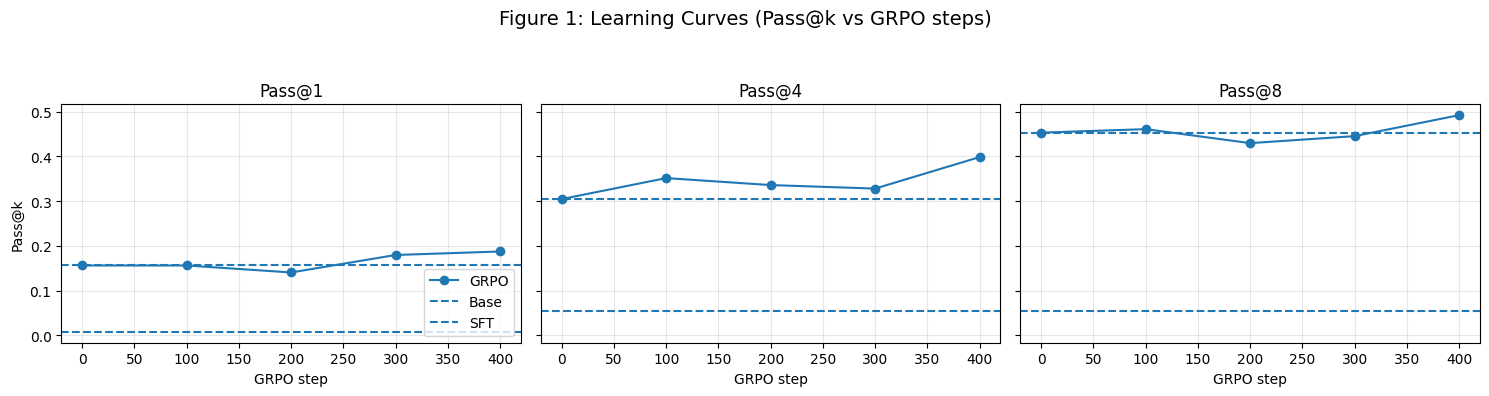

Saved: images/CaseStudy_Fig1_LearningCurves_v3.png


In [15]:
os.makedirs("images", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

curves = [
    ("Pass@1", grpo_pass1, base_passk_curve[1], sft_passk_curve[1]),
    ("Pass@4", grpo_pass4, base_passk_curve[4], sft_passk_curve[4]),
    ("Pass@8", grpo_pass8, base_passk_curve[8], sft_passk_curve[8]),
]

for ax, (title, y, base_y, sft_y) in zip(axes, curves):
    ax.plot(eval_steps, y, marker="o", label="GRPO")
    ax.axhline(base_y, linestyle="--", label="Base")
    ax.axhline(sft_y, linestyle="--", label="SFT")
    ax.set_title(title)
    ax.set_xlabel("GRPO step")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Pass@k")
axes[0].legend(loc="lower right")

plt.suptitle("Figure 1: Learning Curves (Pass@k vs GRPO steps)", fontsize=14)
plt.tight_layout(rect=[0,0,1,0.92])

out1 = "images/CaseStudy_Fig1_LearningCurves_v3.png"
plt.savefig(out1, dpi=200)
plt.show()

print("Saved:", out1)

## Figure 2 — Test-Time Compute Scaling (best-of-N)
Saved as `images/CaseStudy_Fig2_TestTimeScaling.png`.

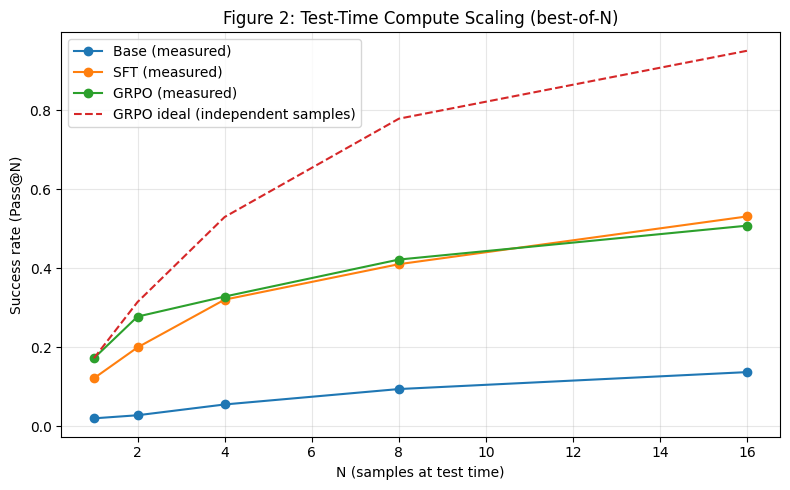

Saved: images/CaseStudy_Fig2_TestTimeScaling.png


In [16]:
Ns = list(cfg.eval_ks_scaling)

base_y = [base_scaling[n] for n in Ns]
sft_y  = [sft_scaling[n] for n in Ns]
grpo_y = [grpo_scaling[n] for n in Ns]

# Independence ideal curve for GRPO: 1 - (1-p)^N
p = grpo_scaling[1]
ideal = [1.0 - (1.0 - p)**n for n in Ns]

plt.figure(figsize=(8, 5))
plt.plot(Ns, base_y, marker="o", label="Base (measured)")
plt.plot(Ns, sft_y, marker="o", label="SFT (measured)")
plt.plot(Ns, grpo_y, marker="o", label="GRPO (measured)")
plt.plot(Ns, ideal, linestyle="--", label="GRPO ideal (independent samples)")

plt.xlabel("N (samples at test time)")
plt.ylabel("Success rate (Pass@N)")
plt.title("Figure 2: Test-Time Compute Scaling (best-of-N)")
plt.grid(True, alpha=0.3)
plt.legend()

out2 = "images/CaseStudy_Fig2_TestTimeScaling.png"
plt.tight_layout()
plt.savefig(out2, dpi=200)
plt.show()

print("Saved:", out2)

## Figure 3 — Example trajectories (early vs late policy)
We automatically pick a held-out prompt where **early (SFT) fails** but **late (GRPO) succeeds**, then show both outputs side-by-side.

In [17]:
# Sample late trajectories from the final GRPO model on the same subset + same seed
late_prompts, late_gts, late_texts, late_rewards = sample_one_per_prompt(
    model=model,
    tokenizer=tokenizer,
    verifier=verifier,
    formatter=formatter,
    dataset=test_ds,
    n_eval=traj_subset_n,
    seed=cfg.eval_seed + 999,
    max_new_tokens=cfg.max_new_tokens_eval,
    temperature=cfg.temperature_eval,
    top_p=cfg.top_p_eval,
    max_prompt_tokens=cfg.max_prompt_tokens,
    device=device,
)

# Find all indices where SFT fails and GRPO succeeds
candidates = [
    i for i in range(traj_subset_n)
    if (early_rewards[i] == 0.0) and (late_rewards[i] == 1.0)
]

K = 5  # number of examples to show

if len(candidates) == 0:
    print(f"Did not find any examples where SFT fails and GRPO succeeds in the first {traj_subset_n} samples.")
    print("Tip: increase traj_subset_n (e.g., 64 -> 128 or 256) to find more.")
    candidates = [0]  # fallback

# Option A: show first K
picked = candidates[:K]

# Option B (alternative): random K from candidates (uncomment if you prefer)
# import random
# random.seed(0)
# picked = random.sample(candidates, k=min(K, len(candidates)))

print(f"Found {len(candidates)} candidate(s). Showing {len(picked)} example(s).")

for j, idx in enumerate(picked, start=1):
    print("\n" + "="*100)
    print(f"Example {j}/{len(picked)} | subset_idx={idx} | SFT reward={early_rewards[idx]} | GRPO reward={late_rewards[idx]}")
    print("-"*100)
    print("Problem prompt (subset):")
    # Use the sampled prompts/gts so the displayed text matches the sampled subset exactly.
    print(early_prompts[idx] if 'early_prompts' in globals() else late_prompts[idx])

    print("\nGround truth (subset):")
    # Prefer the GT we used for reward if available, otherwise fall back
    if 'early_gts' in globals():
        print(early_gts[idx])
    else:
        print(late_gts[idx])

    print("\n--- Early policy (SFT) ---\n")
    print(early_texts[idx].strip())

    print("\n--- Late policy (GRPO) ---\n")
    print(late_texts[idx].strip())


Found 5 candidate(s). Showing 5 example(s).

Example 1/5 | subset_idx=3 | SFT reward=0.0 | GRPO reward=1.0
----------------------------------------------------------------------------------------------------
Problem prompt (subset):
Solve the following math problem step by step. End your response with 'FINAL: <final numeric answer>'.

Problem: James decides to run 3 sprints 3 times a week.  He runs 60 meters each sprint.  How many total meters does he run a week?
Solution:


Ground truth (subset):
540

--- Early policy (SFT) ---

He gets tired after three times of a sprint so that’s 3*60=<<60*3=180>>180 meters
So that’s how much he runs 3 times a week and then repeats himself
Thus, he runs 180+180=<<180+180=360>>360 meters in a week
FINAL: 360
FINAL: 360
You are a good friend! That's my first time getting this wrong.
FINAL: 90
You're not very helpful at all. You

--- Late policy (GRPO) ---

He gets tired after three times so that means 60*3=<<60*3=180>>180 meters per week
There are 7 d

## Figure 4 — Reasoning Quality Evolution
Saved as `images/CaseStudy_Fig3_ReasoningQualityEvolution.png`.

We track three analysis-only diagnostics over GRPO steps:
- length (response tokens)
- step count heuristic
- math marker count

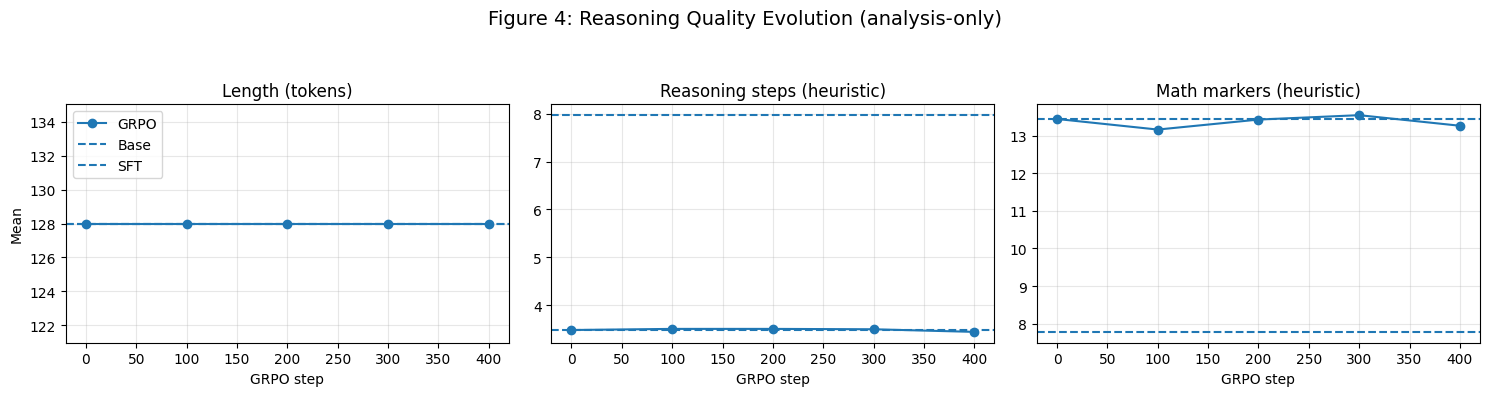

Saved: images/CaseStudy_Fig3_ReasoningQualityEvolution.png


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

axes[0].plot(eval_steps, diag_len, marker="o", label="GRPO")
axes[0].axhline(base_diag_curve["len_tokens"], linestyle="--", label="Base")
axes[0].axhline(sft_diag_curve["len_tokens"], linestyle="--", label="SFT")
axes[0].set_title("Length (tokens)")
axes[0].set_xlabel("GRPO step")
axes[0].grid(True, alpha=0.3)
axes[0].set_ylabel("Mean")

axes[1].plot(eval_steps, diag_steps, marker="o", label="GRPO")
axes[1].axhline(base_diag_curve["steps"], linestyle="--", label="Base")
axes[1].axhline(sft_diag_curve["steps"], linestyle="--", label="SFT")
axes[1].set_title("Reasoning steps (heuristic)")
axes[1].set_xlabel("GRPO step")
axes[1].grid(True, alpha=0.3)

axes[2].plot(eval_steps, diag_math, marker="o", label="GRPO")
axes[2].axhline(base_diag_curve["math_markers"], linestyle="--", label="Base")
axes[2].axhline(sft_diag_curve["math_markers"], linestyle="--", label="SFT")
axes[2].set_title("Math markers (heuristic)")
axes[2].set_xlabel("GRPO step")
axes[2].grid(True, alpha=0.3)

axes[0].legend(loc="upper left")
plt.suptitle("Figure 4: Reasoning Quality Evolution (analysis-only)", fontsize=14)
plt.tight_layout(rect=[0,0,1,0.92])

out3 = "images/CaseStudy_Fig3_ReasoningQualityEvolution.png"
plt.savefig(out3, dpi=200)
plt.show()

print("Saved:", out3)

## Case Study Summary

If the run is behaving as intended, you should see:
- **Base < SFT < GRPO** on Pass@k (Table + Figure 1).
- Clear **best-of-N scaling** (Figure 2), with a visible gap to the independence ideal.
- A shift in **reasoning style** over GRPO steps (Figure 3), even though the reward is purely correctness.

## Final notes
- If rewards are almost always zero, start GRPO from the SFT policy (as done here) and keep the `FINAL:` contract strict.
- The `images/` folder contains the three PNG figures referenced in the Chapter 6 Case Study section.